# Mini-Project 1: UBOS District Population Forecaster

**Question.** A district planning unit needs 5-year population forecasts (2025-2029) to plan primary-school
classrooms. We build a `DistrictPopulation` class, three `Forecaster` subclasses, validate them on a hold-out
period, and turn the best forecast into a classroom estimate.

*Data are illustrative (thousands of people, 2015-2024). Mbarara and Jinja are the two extra districts we added.*
All reusable logic lives in `src/population.py`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))          # so that `from src.xxx import ...` works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                              # fixed seed -> Restart & Run All is reproducible
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

from src.population import (DistrictPopulation, LinearTrendForecaster, CAGRForecaster, FibonacciRatioForecaster,
                            load_districts, evaluate_models, select_best, model_by_name, bootstrap_intervals,
                            additional_classrooms, classrooms_needed, fibonacci, mae, rmse, mape)
import statistics, copy

ModuleNotFoundError: No module named 'matplotlib'

## Task 1 - The `DistrictPopulation` class

In [2]:
districts = load_districts()
for d in districts.values():
    print(repr(d), "| len =", len(d))

# validation demo: every bad input must raise ValueError
bad_inputs = {
    "unequal lengths": ([2015, 2016, 2017], [1, 2]),
    "negative value":  ([2015, 2016], [10, -5]),
    "empty":           ([], []),
    "years not increasing": ([2016, 2015], [1, 2]),
}
for label, (yrs, pop) in bad_inputs.items():
    try:
        DistrictPopulation("bad", yrs, pop)
    except ValueError as err:
        print(f"{label:22s} -> ValueError: {err}")

DistrictPopulation(name='Kampala', years=2015-2024, n=10, last=1800k) | len = 10
DistrictPopulation(name='Wakiso', years=2015-2024, n=10, last=1670k) | len = 10
DistrictPopulation(name='Gulu', years=2015-2024, n=10, last=480k) | len = 10
DistrictPopulation(name='Mbarara', years=2015-2024, n=10, last=263k) | len = 10
DistrictPopulation(name='Jinja', years=2015-2024, n=10, last=630k) | len = 10
unequal lengths        -> ValueError: years and population must have equal length
negative value         -> ValueError: population must not contain negative values
empty                  -> ValueError: years and population must not be empty
years not increasing   -> ValueError: years must be strictly increasing


## Task 2 - Mean, median, variance and standard deviation (`statistics` vs NumPy)

In [3]:
rows = []
for name, d in districts.items():
    s, n0, n1 = d.stats_statistics(), d.stats_numpy(ddof=0), d.stats_numpy(ddof=1)
    rows.append({"district": name, "mean": s["mean"], "median": s["median"],
                 "var statistics.variance": s["variance"], "var np.var (ddof=0)": n0["variance"],
                 "var np.var (ddof=1)": n1["variance"], "sd statistics.stdev": s["stdev"],
                 "sd np.std (ddof=0)": n0["stdev"]})
stats_df = pd.DataFrame(rows).set_index("district")
stats_df

,mean,median,var statistics.variance,var np.var (ddof=0),var np.var (ddof=1),sd statistics.stdev,sd np.std (ddof=0)
district,,,,,,,
Kampala,"1,477.000","1,460.000","42,601.111","38,341.000","42,601.111",206.400,195.809
Wakiso,"1,280.000","1,260.000","60,066.667","54,060.000","60,066.667",245.085,232.508
Gulu,389.500,382.500,"2,885.833","2,597.250","2,885.833",53.720,50.963
Mbarara,226.700,225.500,537.344,483.610,537.344,23.181,21.991
Jinja,548.500,545.000,"2,628.056","2,365.250","2,628.056",51.265,48.634


In [4]:
# The ratio between the two variances is exactly n/(n-1):
d = districts["Kampala"]; n = len(d)
print("statistics.variance / np.var =", d.stats_statistics()["variance"] / d.stats_numpy(0)["variance"])
print("n/(n-1)                      =", n / (n - 1))

statistics.variance / np.var = 1.1111111111111112
n/(n-1)                      = 1.1111111111111112


**Why the numbers differ.** `statistics.variance` divides by *n - 1* (sample variance, Bessel's correction) because we
usually treat the data as a *sample* and the sample mean is estimated from the same data, which makes deviations
slightly too small. `np.var` divides by *n - ddof* and its **default is `ddof=0`** (population variance, divide by *n*).
`ddof` = "delta degrees of freedom": the divisor is `n - ddof`. With `ddof=1` NumPy reproduces `statistics.variance`
exactly (compare the two columns above). With n = 10 the sample variance is 10/9 (about 11 %) larger.
For these ten years is the data a sample or the whole population? It is one realisation of a growth process, so we
prefer the sample version when generalising.

## Task 3 - Year-on-year growth and CAGR

In [5]:
yoy = pd.DataFrame({name: d.growth_rates() * 100 for name, d in districts.items()},
                   index=[f"{y-1}->{y}" for y in districts["Kampala"].years[1:]])
display(yoy.round(2))
cagr = pd.Series({name: d.cagr() * 100 for name, d in districts.items()}, name="CAGR %").sort_values(ascending=False)
display(cagr.to_frame().round(3))
print("Fastest-growing (relative terms):", cagr.index[0])

,Kampala,Wakiso,Gulu,Mbarara,Jinja
2015->2016,4.170,5.260,3.120,2.560,2.080
2016->2017,4.000,7.000,4.550,3.500,3.060
2017->2018,3.850,7.480,4.350,3.380,2.970
2018->2019,5.190,6.090,4.170,3.740,2.880
2019->2020,5.630,6.560,4.000,3.150,3.740
2020->2021,5.330,6.920,5.130,3.490,2.700
2021->2022,4.430,6.470,4.880,3.800,3.510
2022->2023,4.240,6.080,5.810,3.250,3.390
2023->2024,4.650,6.370,5.490,3.540,3.280


,CAGR %
Wakiso,6.469
Kampala,4.608
Gulu,4.608
Mbarara,3.380
Jinja,3.068


Fastest-growing (relative terms): Wakiso


CAGR = (P_last / P_first)^(1/periods) - 1 with **9 periods** (2015 to 2024), not 10. Wakiso grows fastest in *relative*
terms. Kampala and Gulu have an identical CAGR (both 1800/1200 and 480/320 equal 1.5x), a coincidence of the illustrative data.
Kampala is still the largest district, so relative and absolute growth rank differently.

## Task 4 - Three forecasters behind one abstract interface

In [6]:
print("Fibonacci numbers :", fibonacci(12))
fib = fibonacci(14)
print("Successive ratios  :", [round(fib[i+1]/fib[i], 3) for i in range(1, 12)])
print("-> ratios converge to the golden ratio phi =", round((1+5**0.5)/2, 4), "(i.e. +61.8 % per step)")

# All models share fit()/predict(); demonstrate polymorphism on Kampala
d = districts["Kampala"]
for m in [LinearTrendForecaster(), CAGRForecaster(), FibonacciRatioForecaster()]:
    print(f"{m.name:20s}", np.round(m.fit(d.years, d.population).predict(3), 1))

Fibonacci numbers : [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144]
Successive ratios  : [2.0, 1.5, 1.667, 1.6, 1.625, 1.615, 1.619, 1.618, 1.618, 1.618, 1.618]
-> ratios converge to the golden ratio phi = 1.618 (i.e. +61.8 % per step)
Linear trend         [1850.7 1918.6 1986.5]
Exponential (CAGR)   [1882.9 1969.7 2060.5]
Fibonacci ratio      [1885.4 1971.4 2062.6]


`FibonacciRatioForecaster` has two modes. **`raw`** applies the ratio F(k+1)/F(k) directly as the yearly multiplier
(about x1.6 each year) which is the literal reading of the old assignment. **`calibrated`** (used from here on) divides the
ratio by phi and multiplies by the historical growth, so the ratios only add a small damped wiggle around the CAGR. We
critique both in the extension.

## Task 5 - Validate before you forecast (train 2015-2021, test 2022-2024)

In [7]:
best_model = {}
for name, d in districts.items():
    table = pd.DataFrame(evaluate_models(d, 2021)).set_index("model")
    best_model[name] = select_best(table.reset_index().to_dict("records"), key="RMSE")
    print(f"\n=== {name} === best by RMSE: {best_model[name]}")
    display(table.round(3))


=== Kampala === best by RMSE: Exponential (CAGR)


,MAE,RMSE,MAPE_%
model,,,
Linear trend,37.619,38.975,2.165
Exponential (CAGR),9.619,10.385,0.551
Fibonacci ratio,11.479,12.056,0.660



=== Wakiso === best by RMSE: Exponential (CAGR)


,MAE,RMSE,MAPE_%
model,,,
Linear trend,49.405,52.368,3.094
Exponential (CAGR),6.802,8.049,0.420
Fibonacci ratio,9.123,10.007,0.568



=== Gulu === best by RMSE: Fibonacci ratio


,MAE,RMSE,MAPE_%
model,,,
Linear trend,18.571,20.287,4.009
Exponential (CAGR),9.437,10.869,2.025
Fibonacci ratio,9.005,10.515,1.929



=== Mbarara === best by RMSE: Fibonacci ratio


,MAE,RMSE,MAPE_%
model,,,
Linear trend,3.940,4.108,1.538
Exponential (CAGR),1.322,1.353,0.518
Fibonacci ratio,1.128,1.163,0.441



=== Jinja === best by RMSE: Fibonacci ratio


,MAE,RMSE,MAPE_%
model,,,
Linear trend,11.071,11.702,1.800
Exponential (CAGR),6.230,6.612,1.012
Fibonacci ratio,5.821,6.243,0.945


**Selection rule:** smallest RMSE on the hold-out (RMSE penalises large misses; MAE and MAPE agree here). The linear trend is
worst everywhere because population compounds while a straight line cannot. The winner between the exponential and calibrated
Fibonacci models changes by district but the gap is small; with only **3 test points** this is weak evidence, which we return to
in the limitations.

## Task 6 - Forecast 2025-2029 with the selected model (refit on all 10 years)

In [8]:
future_years = np.arange(2025, 2030)
forecast, intervals = {}, {}
for name, d in districts.items():
    model = model_by_name(best_model[name]).fit(d.years, d.population)
    forecast[name] = model.predict(5)
    intervals[name] = bootstrap_intervals(model_by_name(best_model[name]), d.years, d.population,
                                          horizon=5, n_boot=1000, seed=SEED)
fc_df = pd.DataFrame(forecast, index=future_years)
display(fc_df.round(0))

var_rows = []
for name, d in districts.items():
    var_rows.append({"district": name,
                     "var actual 2015-24 (10 yrs)": np.var(d.population, ddof=1),
                     "var actual 2020-24 (5 yrs)": np.var(d.population[-5:], ddof=1),
                     "var forecast 2025-29 (5 yrs)": np.var(forecast[name], ddof=1)})
display(pd.DataFrame(var_rows).set_index("district").round(1))

,Kampala,Wakiso,Gulu,Mbarara,Jinja
2025,"1,883.000","1,778.000",503.000,272.000,650.000
2026,"1,970.000","1,893.000",526.000,281.000,670.000
2027,"2,060.000","2,015.000",550.000,291.000,690.000
2028,"2,155.000","2,146.000",575.000,301.000,711.000
2029,"2,255.000","2,285.000",602.000,311.000,733.000


,var actual 2015-24 (10 yrs),var actual 2020-24 (5 yrs),var forecast 2025-29 (5 yrs)
district,,,
Kampala,"42,601.100","13,700.000","21,607.700"
Wakiso,"60,066.700","21,170.000","40,131.400"
Gulu,"2,885.800","1,270.000","1,536.100"
Mbarara,537.300,180.700,233.400
Jinja,"2,628.100",905.000,"1,086.300"


**Reading the variances.** Variance measures spread *around the series' own mean*, so it depends on the window length.
The 10-year actual series spans a wide range, hence the largest variance. Compared with the like-for-like **5-year** window
(2020-24), the forecast variance is **larger**: compounding growth makes the later values pull further apart. The forecast is a smooth
deterministic curve with **no noise component**, so its variance is entirely trend, whereas real data also contain irregular
year-to-year wobbles. A low forecast variance is therefore *not* evidence of low uncertainty. Forecast variance describes the
shape of the projected path, not how wrong it might be. That is what the prediction intervals below are for.

## Task 7 - Actual, fitted and forecast (with 95 % bootstrap intervals from the extension)

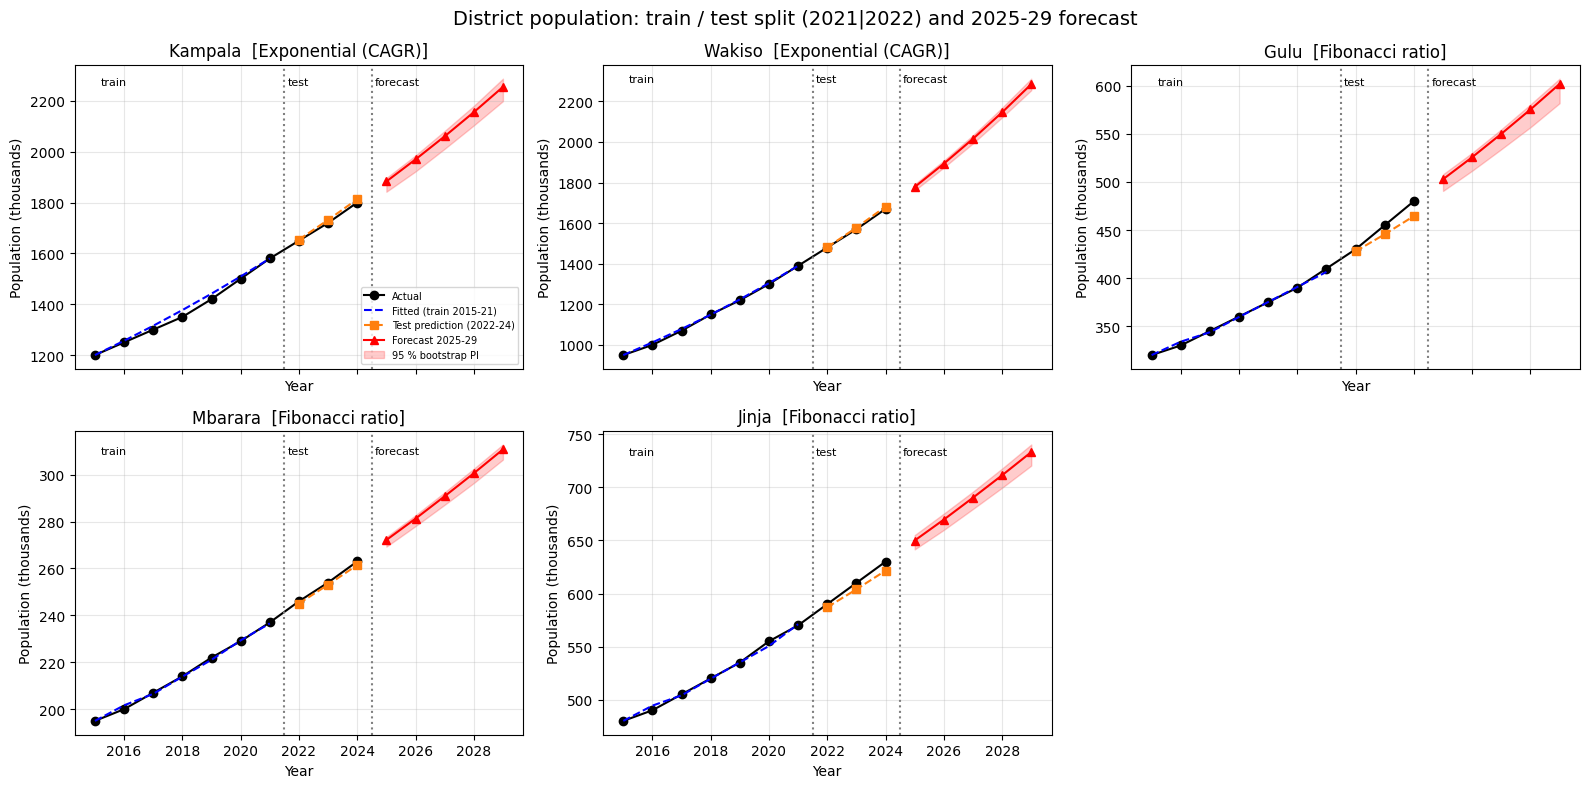

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
axes = axes.ravel()
for ax, (name, d) in zip(axes, districts.items()):
    ty, tp, sy, sp = d.split(2021)
    train_model = model_by_name(best_model[name]).fit(ty, tp)
    ax.plot(d.years, d.population, "ko-", label="Actual")
    ax.plot(ty, train_model.fitted_values(), "b--", label="Fitted (train 2015-21)")
    ax.plot(sy, train_model.predict(len(sy)), "s--", color="tab:orange", label="Test prediction (2022-24)")
    lo, hi = intervals[name]
    ax.plot(future_years, forecast[name], "r^-", label="Forecast 2025-29")
    ax.fill_between(future_years, lo, hi, color="red", alpha=0.2, label="95 % bootstrap PI")
    ax.axvline(2021.5, color="grey", ls=":"); ax.axvline(2024.5, color="grey", ls=":")
    ax.text(2015.2, ax.get_ylim()[1]*0.98, "train", va="top", fontsize=8)
    ax.text(2021.6, ax.get_ylim()[1]*0.98, "test", va="top", fontsize=8)
    ax.text(2024.6, ax.get_ylim()[1]*0.98, "forecast", va="top", fontsize=8)
    ax.set_title(f"{name}  [{best_model[name]}]"); ax.set_ylabel("Population (thousands)"); ax.set_xlabel("Year")
axes[0].legend(fontsize=7, loc="lower right")
axes[-1].axis("off")
fig.suptitle("District population: train / test split (2021|2022) and 2025-29 forecast", fontsize=14)
plt.tight_layout(); plt.show()

## Task 8 - Planning: extra classrooms needed by 2029

In [10]:
rows = []
for name, d in districts.items():
    now, then = d.population[-1], forecast[name][-1]
    lo, hi = intervals[name]
    rows.append({"district": name, "pop 2024 (k)": now, "pop 2029 (k)": then,
                 "classrooms 2024": classrooms_needed(now), "classrooms 2029": classrooms_needed(then),
                 "ADDITIONAL": additional_classrooms(now, then),
                 "additional (PI low)": additional_classrooms(now, lo[-1]),
                 "additional (PI high)": additional_classrooms(now, hi[-1])})
plan = pd.DataFrame(rows).set_index("district")
display(plan.round(0))
print("Total additional classrooms:", int(plan["ADDITIONAL"].sum()))

,pop 2024 (k),pop 2029 (k),classrooms 2024,classrooms 2029,ADDITIONAL,additional (PI low),additional (PI high)
district,,,,,,,
Kampala,"1,800.000","2,255.000",6114,7658,1544,1355,1655
Wakiso,"1,670.000","2,285.000",5672,7760,2088,1987,2180
Gulu,480.000,602.000,1631,2045,414,346,432
Mbarara,263.000,311.000,894,1056,162,147,169
Jinja,630.000,733.000,2140,2491,351,307,375


Total additional classrooms: 4559


Assumptions: 18 % of residents are primary-school age, 53 pupils per classroom, every pupil enrolled, and **rounding up** (a fraction
of a classroom still needs a room). "Additional" = classrooms(2029) - classrooms(2024) with 2024 treated as exactly
sufficient today, which is optimistic because any existing backlog is ignored.

## Extension - Critical assessment of the Fibonacci-ratio model

,raw Fibonacci,calibrated Fibonacci,CAGR
2025,"3,000.000","1,885.000","1,883.000"
2026,"4,800.000","1,971.000","1,970.000"
2027,"7,800.000","2,063.000","2,060.000"
2028,"12,600.000","2,157.000","2,155.000"
2029,"20,400.000","2,257.000","2,255.000"


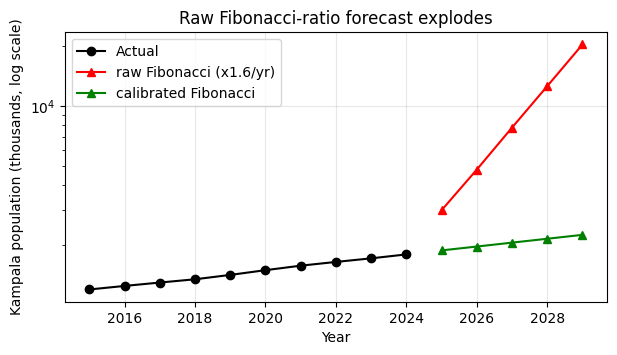

In [11]:
d = districts["Kampala"]
raw = FibonacciRatioForecaster("raw").fit(d.years, d.population).predict(5)
cal = FibonacciRatioForecaster("calibrated").fit(d.years, d.population).predict(5)
cg = CAGRForecaster().fit(d.years, d.population).predict(5)
display(pd.DataFrame({"raw Fibonacci": raw, "calibrated Fibonacci": cal, "CAGR": cg}, index=future_years).round(0))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(d.years, d.population, "ko-", label="Actual")
ax.plot(future_years, raw, "r^-", label="raw Fibonacci (x1.6/yr)")
ax.plot(future_years, cal, "g^-", label="calibrated Fibonacci")
ax.set_yscale("log"); ax.set_xlabel("Year"); ax.set_ylabel("Kampala population (thousands, log scale)")
ax.set_title("Raw Fibonacci-ratio forecast explodes"); ax.legend(); plt.show()

**When is it defensible?** The raw model implies growth of about 60 % a year (ratio to phi = 1.618) whatever the data say. Kampala
would reach about 20 million by 2029. That is defensible only for a population that really multiplies by 1.6 each period
(bacteria in a flask, early epidemic spread), never for a district growing 3-6 % a year. Fibonacci numbers count rabbits under
unlimited resources: no capacity limit, no mortality, no migration. The **calibrated** version is defensible only because it
quietly *becomes the CAGR model*: the ratio divided by phi tends to 1, leaving a small damped oscillation with no demographic
meaning. It cannot beat CAGR in any systematic way. In its favour there is no mechanism. Its apparent success on Gulu,
Mbarara and Jinja is a small-sample artefact of the wobble happening to fit 3 test points.

## Findings & Limitations

## Findings & Limitations

**Findings.** Wakiso is growing fastest in relative terms (CAGR 6.5 % a year against 4.6 % for Kampala and Gulu, 3.4 % for Mbarara
and 3.1 % for Jinja), even though Kampala remains the largest district. On the 2022-24 hold-out the exponential (CAGR) model won for
Kampala and Wakiso and the calibrated Fibonacci model narrowly won for Gulu, Mbarara and Jinja. The linear trend was worst everywhere
(MAPE 1.5-4 %) because it cannot represent compounding. Refitted on all years, the forecasts imply about 1,544, 2,088, 414, 162 and 351
extra classrooms by 2029 for Kampala, Wakiso, Gulu, Mbarara and Jinja respectively, roughly 4,560 in total, and Wakiso, not Kampala, is the district
that most urgently needs construction. Forecast variance exceeds that of the last five actual years because growth compounds;
it says nothing about certainty.

**Limitations.** The data are illustrative, and the training set has only seven points and the test set three, so the model
ranking is fragile (the winning margin is at most about 2 thousand people). All models assume a constant growth regime: no migration shocks,
policy changes, censuses or fertility decline. The bootstrap intervals are narrow (Kampala 2029: about 2,199-2,287 thousand) because
residuals from smooth fits are tiny, and they ignore model-selection uncertainty, so they understate the real risk and should
be read as a lower bound. The 18 % school-age share and the 53-pupil class size are fixed, and enrolment is assumed universal,
which ignores the existing classroom backlog. Real UBOS census data should replace the series before any decision.